# ⚽ สรุปโปรเจกต์: First Score และใบแดงมีผลต่อแพ้ชนะไหม? (ฟุตบอลโลก 1990–2026)

## คำถามที่ต้องการตอบ
1. ทีมที่ยิงประตูแรกชนะ เสมอ หรือแพ้ กี่เปอร์เซ็นต์?
2. ทีมที่ขึ้นนำก่อนเสียความได้เปรียบบ่อยแค่ไหน?
3. ถ้าทีมที่ยิงก่อนโดนใบแดง โอกาสชนะลดลงหรือไม่?

## ข้อมูลที่ใช้
- แหล่งข้อมูล: [openfootball/worldcup.json](https://github.com/openfootball/worldcup.json) (ปี 1990, 1994, 1998, 2002, 2006, 2010, 2014, 2018, 2022, 2026)
- ใช้: รอบการแข่งขัน, ทีม, สกอร์ (FT / ET / จุดโทษ), ประตูพร้อมนาที, ใบแดงของทีมที่ยิงก่อน
- ตัดแมตช์ 0-0 ออก เหลือ **604 แมตช์** บันทึกเป็น `worldcup_first_goals_1990_2026.csv`

## วิธีวิเคราะห์
- หาทีมที่ยิงประตูแรกจากนาทีของประตู
- ตัดสินผลตามลำดับ FT → ET → จุดโทษ
- นับใบแดงของทีมที่ยิงก่อน แล้วแบ่งเป็น `0 ใบแดง` กับ `1+ ใบแดง`

## กราฟในหัวข้อนี้
1. Win / Draw / Loss ของทีมที่ยิงก่อน (แท่ง + วงกลม)
2. จำนวนใบแดงแยกตามผลการแข่งขัน (ไม่รวมจุดโทษ)
3. อัตราชนะ/แพ้ในเวลาปกติ เทียบ 0 ใบแดง กับ 1+ ใบแดง (แท่งซ้อน 100%)

## ข้อควรระวัง
- นับใบแดงทั้งแมตช์ ไม่ได้ดูว่าเกิดก่อนหรือหลังประตูแรก
- แมตช์ที่ทีมยิงก่อนได้ใบแดงมีจำนวนน้อย ผลจึงมีความไม่แน่นอน
- เป็นความสัมพันธ์ ไม่ใช่เหตุและผล

**1. Data Collection and Preprocessing**

รวบรวมข้อมูลการแข่งขันฟุตบอลโลกจาก GitHub ตั้งแต่ปี 1990–2026 แล้วทำความสะอาดและจัดรูปแบบข้อมูล เช่น รอบการแข่งขัน ทีม คะแนน และนาทีที่ยิงประตูแรก พร้อมวิเคราะห์ผลการแข่งขันของทีมที่ยิงประตูแรกและจำนวนใบแดง ก่อนบันทึกข้อมูลเป็นไฟล์ CSV เพื่อนำไปวิเคราะห์และสร้าง Visualization ต่อไป

In [ ]:
import json
import re
import urllib.request
import pandas as pd


def parse_minute(minute_str):
    if minute_str is None:
        return 999
    match = re.search(r"(\d+)", str(minute_str))
    return int(match.group(1)) if match else 999


def map_round_category(round_name):
    if not round_name:
        return "Group"
    r = str(round_name).lower()
    if (
        "final" in r
        and "semi" not in r
        and "quarter" not in r
        and "3rd" not in r
        and "third" not in r
    ):
        return "Final"
    elif "third" in r or "3rd" in r or "three" in r:
        return "3rd"
    elif "semi" in r:
        return "SF"
    elif "quarter" in r:
        return "QF"
    elif "round of 16" in r or "last 16" in r or "r16" in r:
        return "R16"
    elif "round of 32" in r or "last 32" in r or "r32" in r:
        return "R32"
    else:
        return "Group"


def extract_matches_safely(data):
    matches = []
    if isinstance(data, list):
        for item in data:
            if isinstance(item, dict):
                round_title = item.get("name", item.get("round", "Group Stage"))
                for m in item.get("matches", []):
                    if isinstance(m, dict):
                        if "round" not in m:
                            m["round"] = round_title
                        matches.append(m)
    elif isinstance(data, dict):
        if "matches" in data and isinstance(data["matches"], list):
            matches.extend(data["matches"])
        elif "rounds" in data and isinstance(data["rounds"], list):
            for r in data["rounds"]:
                if isinstance(r, dict):
                    round_title = r.get("name", "Group Stage")
                    for m in r.get("matches", []):
                        if isinstance(m, dict):
                            m["round"] = round_title
                            matches.append(m)
    return matches


years = [1990, 1994, 1998, 2002, 2006, 2010, 2014, 2018, 2022, 2026]
rows = []

for year in years:
    url = f"https://raw.githubusercontent.com/openfootball/worldcup.json/master/{year}/worldcup-full.json"
    try:
        req = urllib.request.Request(
            url, headers={"User-Agent": "Mozilla/5.0"}
        )
        with urllib.request.urlopen(req) as response:
            data = json.loads(response.read().decode())
            matches = extract_matches_safely(data)

            for match in matches:
                raw_round = match.get("round", "")
                standard_round = map_round_category(raw_round)

                t1, t2 = match.get("team1"), match.get("team2")
                team1 = (
                    t1.get("name", t1.get("code", "Team 1"))
                    if isinstance(t1, dict)
                    else str(t1 or "Team 1")
                )
                team2 = (
                    t2.get("name", t2.get("code", "Team 2"))
                    if isinstance(t2, dict)
                    else str(t2 or "Team 2")
                )
                match_name = f"{team1} vs. {team2}"

                raw_score = match.get("score")
                if not raw_score:
                    continue

                ft_score, et_score, p_score = None, None, None
                if isinstance(raw_score, dict):
                    ft_score = raw_score.get("ft")
                    et_score = raw_score.get("et")
                    p_score = raw_score.get("p")
                    final_score_list = (
                        et_score
                        if et_score is not None
                        else (ft_score if ft_score is not None else None)
                    )
                elif isinstance(raw_score, list):
                    final_score_list = raw_score
                    ft_score = raw_score

                if not final_score_list or len(final_score_list) < 2:
                    continue

                final_score_str = (
                    f"{final_score_list[0]} - {final_score_list[1]}"
                )
                if p_score:
                    final_score_str += f" (p. {p_score[0]}-{p_score[1]})"

                # Extract Goals
                all_goals = []
                for g in match.get("goals1", []):
                    if isinstance(g, dict):
                        all_goals.append(
                            {"team": team1, "min": g.get("minute", 999)}
                        )
                for g in match.get("goals2", []):
                    if isinstance(g, dict):
                        all_goals.append(
                            {"team": team2, "min": g.get("minute", 999)}
                        )

                if (
                    not all_goals
                    and "goals" in match
                    and isinstance(match["goals"], list)
                ):
                    for g in match["goals"]:
                        if isinstance(g, dict):
                            team_num = g.get("team")
                            scorer_team = (
                                team1
                                if team_num == 1
                                else (team2 if team_num == 2 else None)
                            )
                            if scorer_team:
                                all_goals.append(
                                    {
                                        "team": scorer_team,
                                        "min": g.get("minute", 999),
                                    }
                                )

                if not all_goals:
                    continue  # Ignore 0-0s

                all_goals.sort(key=lambda x: parse_minute(x["min"]))
                first_scorer = all_goals[0]["team"]
                first_min = (
                    f"{all_goals[0]['min']}'"
                    if all_goals[0]["min"] != 999
                    else "N/A"
                )

                # Determine Winner Hierarchy: FT -> ET -> P
                ft_winner = (
                    team1
                    if ft_score and ft_score[0] > ft_score[1]
                    else (
                        team2
                        if ft_score and ft_score[1] > ft_score[0]
                        else "Draw"
                    )
                )
                et_winner = (
                    team1
                    if et_score and et_score[0] > et_score[1]
                    else (
                        team2
                        if et_score and et_score[1] > et_score[0]
                        else "Draw"
                    )
                )
                p_winner = (
                    team1
                    if p_score and p_score[0] > p_score[1]
                    else (
                        team2
                        if p_score and p_score[1] > p_score[0]
                        else "Draw"
                    )
                )

                if ft_winner == first_scorer:
                    outcome = "Win (FT)"
                elif ft_winner != "Draw":
                    outcome = "Loss (FT)"
                elif et_score is not None and et_winner == first_scorer:
                    outcome = "Win (ET)"
                elif et_score is not None and et_winner != "Draw":
                    outcome = "Loss (ET)"
                elif p_score is not None and p_winner == first_scorer:
                    outcome = "Win (P)"
                elif p_score is not None and p_winner != "Draw":
                    outcome = "Loss (P)"
                else:
                    outcome = "Draw"

                # Extract Red Cards for First Goal Scoring Team
                first_scorer_rc = 0

                # Variant A: bookings [[team1_cards], [team2_cards]]
                bookings = match.get("bookings", [])
                if isinstance(bookings, list) and len(bookings) == 2:
                    scorer_bookings = (
                        bookings[0] if first_scorer == team1 else bookings[1]
                    )
                    if isinstance(scorer_bookings, list):
                        for card in scorer_bookings:
                            if isinstance(card, dict) and card.get(
                                "type"
                            ) in ["R", "SY", "red"]:
                                first_scorer_rc += 1

                # Variant B: Flat cards list with team property
                cards = match.get("cards", [])
                if isinstance(cards, list):
                    for card in cards:
                        if isinstance(card, dict) and card.get("type") in [
                            "R",
                            "SY",
                            "red",
                        ]:
                            c_team = card.get("team")
                            if (
                                (c_team == 1 and first_scorer == team1)
                                or (c_team == 2 and first_scorer == team2)
                                or (c_team == first_scorer)
                            ):
                                first_scorer_rc += 1

                rows.append(
                    {
                        "Year": year,
                        "Round": standard_round,
                        "Match": match_name,
                        "First Scoring Country": first_scorer,
                        "First Goal Minute": first_min,
                        "Final Score": final_score_str,
                        "First Scorer Outcome": outcome,
                        "First Scorer Red Cards": first_scorer_rc,
                    }
                )

    except Exception as e:
        print(f"Error reading {year}: {e}")

df = pd.DataFrame(rows)
df.to_csv("worldcup_first_goals_1990_2026.csv", index=False)
print(f"Exported {len(df)} matches to worldcup_first_goals_1990_2026.csv")

Exported 604 matches to worldcup_first_goals_1990_2026.csv


**2. Data Visualization and Outcome Analysis**

วิเคราะห์ผลการแข่งขันฟุตบอลโลกตั้งแต่ปี 1990–2026 โดยสร้างกราฟแท่งและกราฟวงกลม เพื่อเปรียบเทียบผลการแข่งขันของทีมที่ยิงประตูแรก ได้แก่ ชนะ เสมอ และแพ้ พร้อมแสดงจำนวนและเปอร์เซ็นต์ของแต่ละผลลัพธ์ โดยแยกผลการแข่งขันในเวลาปกติ ช่วงต่อเวลาพิเศษ และการดวลจุดโทษ เพื่อศึกษาว่าทีมที่ยิงประตูแรกมีโอกาสชนะการแข่งขันมากน้อยเพียงใด

Successfully processed and saved 604 scored matches (0-0 draws excluded).


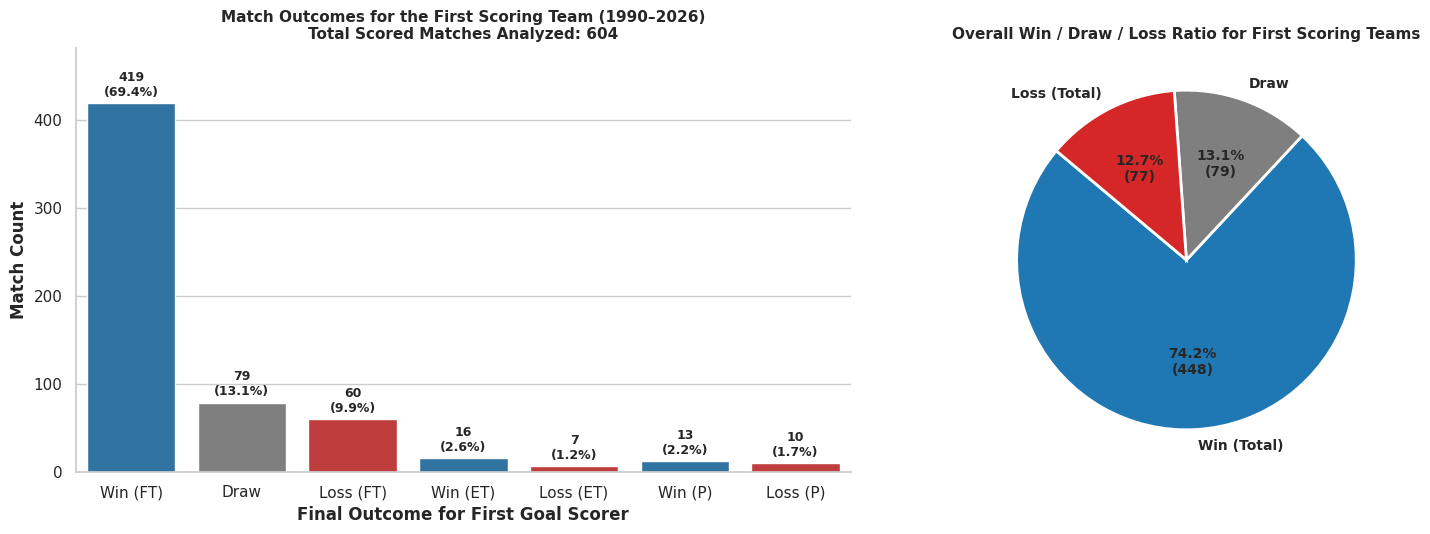

In [ ]:
import json
import re
import urllib.request
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# =============================================================
# STEP 1: EXTRACTION & DATA PARSING
# =============================================================


def parse_minute(minute_str):
    if minute_str is None:
        return 999
    match = re.search(r"(\d+)", str(minute_str))
    return int(match.group(1)) if match else 999


def map_round_category(round_name):
    if not round_name:
        return "Group"
    r = str(round_name).lower()
    if (
        "final" in r
        and "semi" not in r
        and "quarter" not in r
        and "3rd" not in r
        and "third" not in r
    ):
        return "Final"
    elif "third" in r or "3rd" in r or "three" in r:
        return "3rd"
    elif "semi" in r:
        return "SF"
    elif "quarter" in r:
        return "QF"
    elif "round of 16" in r or "last 16" in r or "r16" in r:
        return "R16"
    elif "round of 32" in r or "last 32" in r or "r32" in r:
        return "R32"
    else:
        return "Group"


def extract_matches_safely(data):
    matches = []
    if isinstance(data, list):
        for item in data:
            if isinstance(item, dict):
                round_title = item.get("name", item.get("round", "Group Stage"))
                for m in item.get("matches", []):
                    if isinstance(m, dict):
                        if "round" not in m:
                            m["round"] = round_title
                        matches.append(m)
    elif isinstance(data, dict):
        if "matches" in data and isinstance(data["matches"], list):
            matches.extend(data["matches"])
        elif "rounds" in data and isinstance(data["rounds"], list):
            for r in data["rounds"]:
                if isinstance(r, dict):
                    round_title = r.get("name", "Group Stage")
                    for m in r.get("matches", []):
                        if isinstance(m, dict):
                            m["round"] = round_title
                            matches.append(m)
    return matches


years = [1990, 1994, 1998, 2002, 2006, 2010, 2014, 2018, 2022, 2026]
rows = []

for year in years:
    url = f"https://raw.githubusercontent.com/openfootball/worldcup.json/master/{year}/worldcup-full.json"
    try:
        req = urllib.request.Request(
            url, headers={"User-Agent": "Mozilla/5.0"}
        )
        with urllib.request.urlopen(req) as response:
            data = json.loads(response.read().decode())
            matches = extract_matches_safely(data)

            for match in matches:
                raw_round = match.get("round", "")
                standard_round = map_round_category(raw_round)

                t1, t2 = match.get("team1"), match.get("team2")
                team1 = (
                    t1.get("name", t1.get("code", "Team 1"))
                    if isinstance(t1, dict)
                    else str(t1 or "Team 1")
                )
                team2 = (
                    t2.get("name", t2.get("code", "Team 2"))
                    if isinstance(t2, dict)
                    else str(t2 or "Team 2")
                )
                match_name = f"{team1} vs. {team2}"

                raw_score = match.get("score")
                if not raw_score:
                    continue  # Skip unplayed fixtures

                ft_score, et_score, p_score = None, None, None
                if isinstance(raw_score, dict):
                    ft_score = raw_score.get("ft")
                    et_score = raw_score.get("et")
                    p_score = raw_score.get("p")
                    final_score_list = (
                        et_score
                        if et_score is not None
                        else (ft_score if ft_score is not None else None)
                    )
                elif isinstance(raw_score, list):
                    final_score_list = raw_score
                    ft_score = raw_score

                if not final_score_list or len(final_score_list) < 2:
                    continue

                # EXCLUDE GOALLESS DRAWS (0-0)
                if final_score_list[0] == 0 and final_score_list[1] == 0:
                    continue

                final_score_str = (
                    f"{final_score_list[0]} - {final_score_list[1]}"
                )
                if p_score:
                    final_score_str += f" (p. {p_score[0]}-{p_score[1]})"

                # Parse Goals Robustly Across Schema Variations
                all_goals = []

                # Format A: Separate goals1 & goals2 lists
                for g in match.get("goals1", []):
                    if isinstance(g, dict):
                        all_goals.append(
                            {"team": team1, "min": g.get("minute", 999)}
                        )
                for g in match.get("goals2", []):
                    if isinstance(g, dict):
                        all_goals.append(
                            {"team": team2, "min": g.get("minute", 999)}
                        )

                # Format B: Single goals list
                if (
                    not all_goals
                    and "goals" in match
                    and isinstance(match["goals"], list)
                ):
                    for g in match["goals"]:
                        if isinstance(g, dict):
                            team_val = g.get("team")
                            scorer_team = None

                            if team_val in [1, "1", "team1", team1]:
                                scorer_team = team1
                            elif team_val in [2, "2", "team2", team2]:
                                scorer_team = team2

                            # Fallback using running score
                            if not scorer_team and "score" in g:
                                sc = g.get("score")
                                if isinstance(sc, list) and len(sc) == 2:
                                    scorer_team = (
                                        team1 if sc[0] > 0 else team2
                                    )

                            if scorer_team:
                                all_goals.append(
                                    {
                                        "team": scorer_team,
                                        "min": g.get("minute", 999),
                                    }
                                )

                if not all_goals:
                    continue  # Safety check

                all_goals.sort(key=lambda x: parse_minute(x["min"]))
                first_scorer = all_goals[0]["team"]
                first_min = (
                    f"{all_goals[0]['min']}'"
                    if all_goals[0]["min"] != 999
                    else "N/A"
                )

                # Winner Analysis: FT -> ET -> Penalties
                ft_winner = (
                    team1
                    if ft_score and ft_score[0] > ft_score[1]
                    else (
                        team2
                        if ft_score and ft_score[1] > ft_score[0]
                        else "Draw"
                    )
                )
                et_winner = (
                    team1
                    if et_score and et_score[0] > et_score[1]
                    else (
                        team2
                        if et_score and et_score[1] > et_score[0]
                        else "Draw"
                    )
                )
                p_winner = (
                    team1
                    if p_score and p_score[0] > p_score[1]
                    else (
                        team2
                        if p_score and p_score[1] > p_score[0]
                        else "Draw"
                    )
                )

                if ft_winner == first_scorer:
                    outcome = "Win (FT)"
                    lead_held = "Yes"
                elif ft_winner != "Draw":
                    outcome = "Loss (FT)"
                    lead_held = "No (Surrendered)"
                elif et_score is not None and et_winner == first_scorer:
                    outcome = "Win (ET)"
                    lead_held = "Yes"
                elif et_score is not None and et_winner != "Draw":
                    outcome = "Loss (ET)"
                    lead_held = "No (Surrendered)"
                elif p_score is not None and p_winner == first_scorer:
                    outcome = "Win (P)"
                    lead_held = "Yes (Via Penalties)"
                elif p_score is not None and p_winner != "Draw":
                    outcome = "Loss (P)"
                    lead_held = "No (Surrendered)"
                else:
                    outcome = "Draw"
                    lead_held = "No (Surrendered)"

                rows.append(
                    {
                        "Year": year,
                        "Round": standard_round,
                        "Match": match_name,
                        "First Scoring Country": first_scorer,
                        "First Goal Minute": first_min,
                        "Final Score": final_score_str,
                        "First Scorer Outcome": outcome,
                        "Lead Held?": lead_held,
                    }
                )

    except Exception as e:
        print(f"Could not process {year}: {e}")

df = pd.DataFrame(rows)
df.to_csv("worldcup_first_goals_1990_2026.csv", index=False)
print(
    f"Successfully processed and saved {len(df)} scored matches (0-0 draws excluded)."
)


# =============================================================
# STEP 2: VISUALIZATION
# =============================================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

detailed_order = [
    "Win (FT)",
    "Draw",
    "Loss (FT)",
    "Win (ET)",
    "Loss (ET)",
    "Win (P)",
    "Loss (P)",
]

# Calculate Counts
outcome_counts = (
    df["First Scorer Outcome"].value_counts().reindex(detailed_order).fillna(0)
)
detailed_df = pd.DataFrame(
    {"Outcome": outcome_counts.index, "Match Count": outcome_counts.values}
)

# UNIFIED PALETTE: All Wins = Dark Blue, Draw = Gray, All Losses = Dark Red
palette = {
    "Win (FT)": "#1f77b4",
    "Win (ET)": "#1f77b4",
    "Win (P)": "#1f77b4",
    "Draw": "#7f7f7f",
    "Loss (FT)": "#d62728",
    "Loss (ET)": "#d62728",
    "Loss (P)": "#d62728",
}

bar_chart = sns.barplot(
    data=detailed_df,
    x="Outcome",
    y="Match Count",
    hue="Outcome",
    palette=palette,
    legend=False,
    ax=axes[0],
)

for p in bar_chart.patches:
    height = p.get_height()
    if height > 0:
        pct = (height / len(df)) * 100
        axes[0].annotate(
            f"{int(height)}\n({pct:.1f}%)",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
            xytext=(0, 3),
            textcoords="offset points",
        )

axes[0].set_title(
    f"Match Outcomes for the First Scoring Team (1990–2026)\nTotal Scored Matches Analyzed: {len(df)}",
    fontsize=11,
    fontweight="bold",
)
axes[0].set_ylabel("Match Count", fontweight="bold")
axes[0].set_xlabel("Final Outcome for First Goal Scorer", fontweight="bold")
axes[0].set_ylim(0, max(detailed_df["Match Count"]) * 1.15)

# Pie Chart (Aggregated Outcome)


def aggregate_outcome(outcome):
    if "Win" in str(outcome):
        return "Win (Total)"
    elif "Loss" in str(outcome):
        return "Loss (Total)"
    else:
        return "Draw"


df["Aggregated Outcome"] = df["First Scorer Outcome"].apply(aggregate_outcome)
agg_counts = (
    df["Aggregated Outcome"]
    .value_counts()
    .reindex(["Win (Total)", "Draw", "Loss (Total)"])
    .fillna(0)
)


def make_autopct(values):
    def my_autopct(pct):
        total = sum(values)
        val = int(round(pct * total / 100.0))
        return f"{pct:.1f}%\n({val})"

    return my_autopct


axes[1].pie(
    agg_counts.values,
    labels=agg_counts.index,
    autopct=make_autopct(agg_counts.values),
    startangle=140,
    colors=["#1f77b4", "#7f7f7f", "#d62728"],  # Blue, Gray, Red
    textprops={"fontsize": 10, "fontweight": "bold"},
    wedgeprops={"edgecolor": "white", "linewidth": 2},
)

axes[1].set_title(
    "Overall Win / Draw / Loss Ratio for First Scoring Teams",
    fontsize=11,
    fontweight="bold",
)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

**3. Red Card Analysis by Match Outcome**

วิเคราะห์ความสัมพันธ์ระหว่างจำนวนใบแดงของทีมที่ยิงประตูแรกกับผลการแข่งขัน โดยใช้ Stacked Bar Chart แสดงจำนวนแมตช์ที่ไม่มีใบแดงและมีใบแดงตั้งแต่ 1 ใบขึ้นไปในแต่ละผลลัพธ์ ได้แก่ ชนะ เสมอ และแพ้ ทั้งในเวลาปกติและช่วงต่อเวลาพิเศษ โดยไม่รวมผลจากการดวลจุดโทษ เพื่อศึกษาว่าการได้รับใบแดงมีแนวโน้มสัมพันธ์กับโอกาสชนะหรือแพ้ของทีมที่ยิงประตูแรกอย่างไร

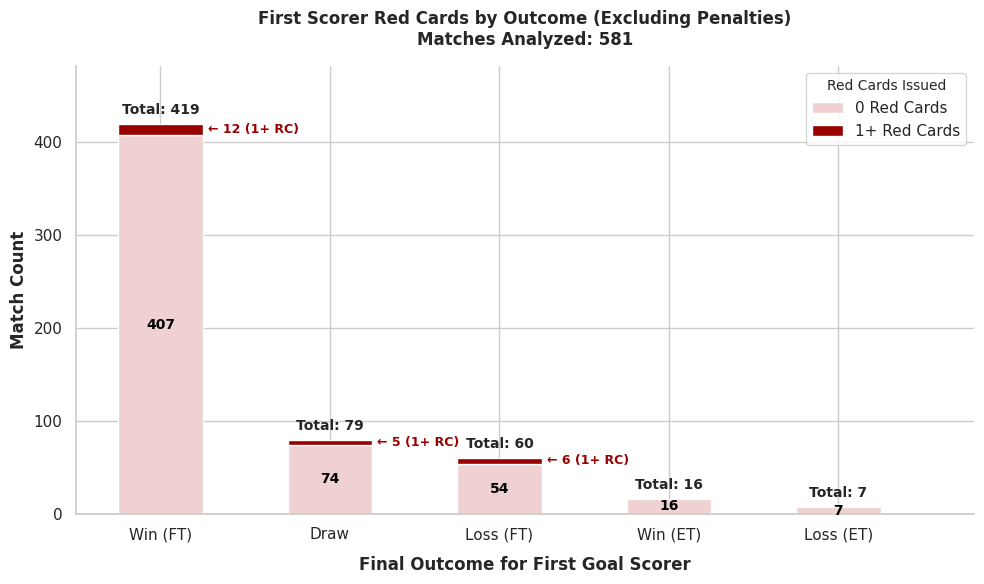

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

# Filter dataset to remove Penalty outcomes
filtered_order = ["Win (FT)", "Draw", "Loss (FT)", "Win (ET)", "Loss (ET)"]
df_filtered = df[df["First Scorer Outcome"].isin(filtered_order)].copy()

# Bin red cards into binary categories
df_filtered["Red Card Category"] = df_filtered["First Scorer Red Cards"].apply(
    lambda x: "0 Red Cards" if x == 0 else "1+ Red Cards"
)

# Aggregate counts with cross-tabulation
ct = pd.crosstab(
    df_filtered["First Scorer Outcome"], df_filtered["Red Card Category"]
).reindex(filtered_order)

for col in ["0 Red Cards", "1+ Red Cards"]:
    if col not in ct.columns:
        ct[col] = 0

ct = ct[["0 Red Cards", "1+ Red Cards"]]

# Plot Stacked Bars in Red Tones (Light Red for 0 RC, Dark Red for 1+ RC)
colors = ["#f0d1d1", "#990000"]
ct.plot(
    kind="bar", stacked=True, color=colors, ax=ax, width=0.5, edgecolor="white"
)

total_filtered_matches = len(df_filtered)
totals = ct.sum(axis=1)

# Annotate segment counts safely
for match_idx, outcome in enumerate(filtered_order):
    no_rc_count = ct.loc[outcome, "0 Red Cards"]
    rc_count = ct.loc[outcome, "1+ Red Cards"]

    # 1. Label 0 Red Cards segment inside the bar (Black text for high contrast on light red)
    if no_rc_count > 0:
        y_pos = no_rc_count / 2
        ax.annotate(
            f"{int(no_rc_count)}",
            (match_idx, y_pos),
            ha="center",
            va="center",
            color="black",
            fontsize=10,
            fontweight="bold",
        )

    # 2. Label 1+ Red Cards segment with side arrow callout (e.g. ← 12 (1+ RC))
    if rc_count > 0:
        y_pos = no_rc_count + (rc_count / 2)
        ax.annotate(
            f"← {int(rc_count)} (1+ RC)",
            xy=(match_idx + 0.26, y_pos),
            xytext=(match_idx + 0.28, y_pos),
            ha="left",
            va="center",
            color="#990000",
            fontsize=9,
            fontweight="bold",
        )

# Add Total count above each bar
for i, total in enumerate(totals):
    if total > 0:
        ax.annotate(
            f"Total: {int(total)}",
            (i, total),
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
            xytext=(0, 5),
            textcoords="offset points",
        )

# Expand X limit slightly on the right so the rightmost callout text isn't cut off
ax.set_xlim(-0.5, len(filtered_order) - 0.2)
ax.set_ylim(0, max(totals) * 1.15)

# Chart Formatting
ax.set_title(
    f"First Scorer Red Cards by Outcome (Excluding Penalties)\nMatches Analyzed: {total_filtered_matches}",
    fontsize=12,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel(
    "Final Outcome for First Goal Scorer", fontweight="bold", labelpad=10
)
ax.set_ylabel("Match Count", fontweight="bold")
ax.tick_params(axis="x", rotation=0)

ax.legend(
    title="Red Cards Issued",
    title_fontsize="10",
    loc="upper right",
    frameon=True,
    facecolor="white",
)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

**4. Red Cards and Win Rate in Full Time**

วิเคราะห์ความสัมพันธ์ระหว่างการได้รับใบแดงกับโอกาสชนะของทีมที่ยิงประตูแรก โดยใช้ 100% Stacked Bar Chart เปรียบเทียบอัตราการชนะและแพ้ในเวลาปกติ ระหว่างทีมที่ไม่มีใบแดงกับทีมที่ได้รับใบแดงตั้งแต่ 1 ใบขึ้นไป พร้อมแสดงเปอร์เซ็นต์และจำนวนแมตช์ของแต่ละกลุ่ม เพื่อศึกษาว่าการได้รับใบแดงสัมพันธ์กับโอกาสชนะของทีมที่ยิงประตูแรกอย่างไร โดยไม่รวมผลเสมอ การต่อเวลาพิเศษ และการดวลจุดโทษ

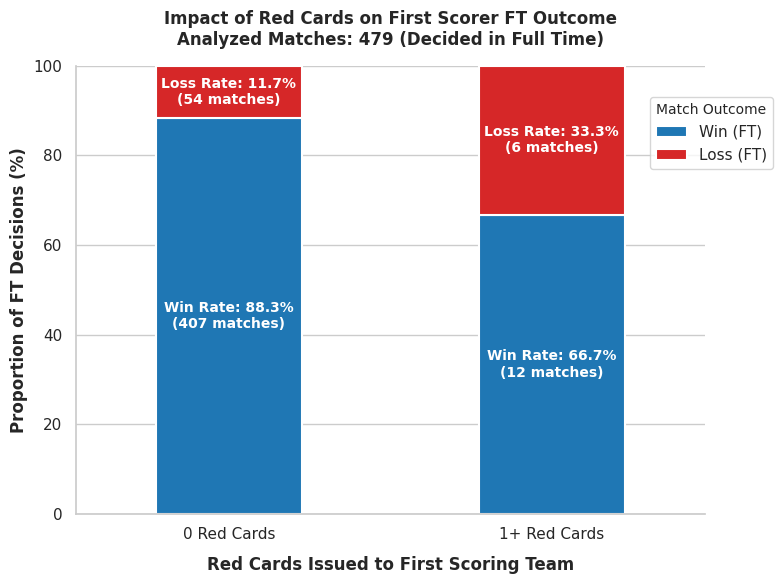

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(8, 6))

# 1. Filter dataset strictly for Win (FT) and Loss (FT)
ft_outcomes = ["Win (FT)", "Loss (FT)"]
df_ft = df[df["First Scorer Outcome"].isin(ft_outcomes)].copy()

# 2. Bin red cards into binary groups
df_ft["Red Card Status"] = df_ft["First Scorer Red Cards"].apply(
    lambda x: "0 Red Cards" if x == 0 else "1+ Red Cards"
)

# 3. Create cross-tabulation of Counts
ct_counts = pd.crosstab(
    df_ft["Red Card Status"], df_ft["First Scorer Outcome"]
)[ft_outcomes]

# 4. Normalize rows to get exact Percentages (100% total per bar)
ct_props = ct_counts.div(ct_counts.sum(axis=1), axis=0) * 100

# 5. Plot 100% Stacked Bar Chart
colors = ["#1f77b4", "#d62728"]  # Green for Win, Red for Loss
ct_props.plot(
    kind="bar",
    stacked=True,
    color=colors,
    ax=ax,
    width=0.45,
    edgecolor="white",
    linewidth=1.5,
)

# -------------------------------------------------------------
# ANNOTATE SEGMENTS WITH PERCENTAGES & RAW COUNTS
# -------------------------------------------------------------
for i, status in enumerate(ct_props.index):
    win_pct = ct_props.loc[status, "Win (FT)"]
    loss_pct = ct_props.loc[status, "Loss (FT)"]

    win_count = ct_counts.loc[status, "Win (FT)"]
    loss_count = ct_counts.loc[status, "Loss (FT)"]

    # Annotate Win % (Green Segment)
    ax.annotate(
        f"Win Rate: {win_pct:.1f}%\n({int(win_count)} matches)",
        (i, win_pct / 2),
        ha="center",
        va="center",
        color="white",
        fontsize=10,
        fontweight="bold",
    )

    # Annotate Loss % (Red Segment)
    ax.annotate(
        f"Loss Rate: {loss_pct:.1f}%\n({int(loss_count)} matches)",
        (i, win_pct + (loss_pct / 2)),
        ha="center",
        va="center",
        color="white",
        fontsize=10,
        fontweight="bold",
    )

# -------------------------------------------------------------
# CHART FORMATTING
# -------------------------------------------------------------
ax.set_title(
    f"Impact of Red Cards on First Scorer FT Outcome\nAnalyzed Matches: {len(df_ft)} (Decided in Full Time)",
    fontsize=12,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("Red Cards Issued to First Scoring Team", fontweight="bold", labelpad=10)
ax.set_ylabel("Proportion of FT Decisions (%)", fontweight="bold")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)

# Legend Configuration (Moved outside to the right)
ax.legend(
    ["Win (FT)", "Loss (FT)"],
    title="Match Outcome",
    title_fontsize="10",
    loc="center left",
    bbox_to_anchor=(0.9, 0.85),
    frameon=True,
    facecolor="white",
)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

## สรุปผลการวิเคราะห์จากกราฟทั้ง 3 รูป

### 1. ผลการแข่งขันของทีมที่ยิงประตูแรก

- จากการแข่งขันที่นำมาวิเคราะห์ทั้งหมด 604 นัด ทีมที่ยิงประตูแรกชนะในเวลาปกติมากที่สุด 419 นัด (69.4%)
- เมื่อรวมการต่อเวลาพิเศษและการดวลจุดโทษ ทีมที่ยิงประตูแรกชนะทั้งหมด 448 นัด (74.2%)
- แพ้รวม 87 นัด (14.4%) และเสมอ 79 นัด (13.1%)

ข้อสรุป: ทีมที่ยิงประตูแรกมีแนวโน้มชนะการแข่งขันสูง โดยประมาณ 74.2% ของแมตช์ที่วิเคราะห์ ทีมดังกล่าวเป็นฝ่ายชนะ

### 2. จำนวนใบแดงกับผลการแข่งขัน

- จาก 581 นัดที่ไม่รวมการดวลจุดโทษ ทีมที่ยิงประตูแรกและชนะในเวลาปกติ 419 นัด มี 12 นัดที่ทีมได้รับใบแดงอย่างน้อย 1 ใบ
- ในกลุ่มที่เสมอ 79 นัด มี 5 นัดที่ทีมได้รับใบแดง
- ในกลุ่มที่แพ้ในเวลาปกติ 60 นัด มี 6 นัดที่ทีมได้รับใบแดง
- กลุ่มที่ชนะหรือแพ้ในช่วงต่อเวลาพิเศษมีจำนวนแมตช์น้อยกว่า และในกราฟนี้ไม่พบใบแดงในทีมที่ยิงประตูแรก

ข้อสรุป: ในข้อมูลชุดนี้ ทีมที่ยิงประตูแรกและได้รับใบแดงพบได้ทั้งในกลุ่มที่ชนะ เสมอ และแพ้ จึงยังสรุปไม่ได้จากจำนวนแมตช์เพียงอย่างเดียวว่าใบแดงทำให้ทีมแพ้

### 3. เปรียบเทียบอัตราชนะและแพ้ในเวลาปกติกับจำนวนใบแดง

จากทั้งหมด 479 นัดที่ผลการแข่งขันตัดสินในเวลาปกติ:

| สถานะใบแดงของทีมที่ยิงประตูแรก | ชนะในเวลาปกติ   | แพ้ในเวลาปกติ  |
| ------------------------------ | --------------- | -------------- |
| ไม่มีใบแดง                     | 88.3% (407 นัด) | 11.7% (54 นัด) |
| มีใบแดงตั้งแต่ 1 ใบขึ้นไป      | 66.7% (12 นัด)  | 33.3% (6 นัด)  |

ข้อสรุป: กลุ่มที่มีใบแดงมีอัตราชนะในเวลาปกติต่ำกว่ากลุ่มที่ไม่มีใบแดง โดยต่างกัน 21.6 จุดเปอร์เซ็นต์ และมีอัตราแพ้สูงกว่า อย่างไรก็ตาม กลุ่มที่มีใบแดงมีเพียง 18 นัด จึงควรระมัดระวังในการตีความผล

## ภาพรวม

ผลการวิเคราะห์แสดงให้เห็นว่า การยิงประตูแรกสัมพันธ์กับโอกาสชนะที่สูงขึ้น และการได้รับใบแดงอาจสัมพันธ์กับโอกาสชนะที่ลดลง ในกลุ่มทีมที่ยิงประตูแรก แต่ข้อมูลนี้แสดงความสัมพันธ์ ไม่ได้ยืนยันว่าใบแดงเป็นสาเหตุโดยตรงที่ทำให้ทีมแพ้ เพราะยังมีปัจจัยอื่น เช่น ความแข็งแกร่งของทีม เวลาในการได้รับใบแดง และสถานการณ์ของการแข่งขัน